# RSI pullback strategy on a halal universe

A shorter-term, mean-reversion counterpart to the breakout notebook: instead of buying strength,
this waits for a temporary dip inside a stock that's still in a long-term uptrend. Tickers come
from `equities-list.csv` (rows with `Asset Type == Stock`; the ETFs in that file are excluded).
The CSV labels these as halal *candidates* only — independently verify current Shariah compliance
before investing.

**Strategy specification**

- **Universe filter** — a stock is only ever considered while its close is above its own 200-day
  SMA. The long-term uptrend has to be intact for a dip to be a "pullback" rather than the start of
  a real decline.
- **Entry (armed)** — while in that uptrend, if 14-day RSI drops below 35, the name is marked
  *armed*: temporarily oversold, worth watching for a recovery.
- **Confirmation (buy)** — the actual trade only fires once price crosses back above its 20-day
  SMA — the pullback has to show signs of reversing before this buys in, rather than trying to
  catch the falling knife the moment RSI dips. A name stays armed (no expiry) until either this
  confirmation fires or price falls back below the 200-day SMA, which invalidates the setup.
- **Exit** — sell when 14-day RSI rises back above 60, *or* the position is up 10%, whichever
  comes first.
- **Position management** — long only, one position per name at a time, up to 15 concurrent
  positions, each sized as an equal share of current portfolio value at entry. When more than 15
  names confirm on the same day, the most oversold ones (lowest RSI) get the open slots first.

As the spec puts it: *"I only want to buy temporarily weak stocks that are still in long-term
uptrends"* — deliberately not the same thing as blindly buying RSI < 30. Like the breakout
notebook, this trades on a daily signal rather than a monthly calendar, so it runs the same kind
of day-by-day event-driven simulation, reusing the shared `data/daily/{TICKER}.csv` OHLC cache.

## Before running

1. Install dependencies: `pip install ib-insync pandas numpy matplotlib pandas-datareader`
2. Run IBKR Trader Workstation or IB Gateway, enable API connections, and use a market-data-enabled
   account.
3. Set the host, port, and client ID below. Typical paper ports are 7497 for TWS and 4002 for
   Gateway; live ports are commonly 7496 and 4001.
4. Run the acquisition cell once. It shares the same `data/daily/{TICKER}.csv` cache as the other
   notebooks, so if you've already run one of those, this one has nothing left to fetch.

In [1]:
from pathlib import Path
import csv
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from ib_insync import IB, Stock, util
except ImportError as exc:
    raise ImportError('Install ib-insync first: pip install ib-insync') from exc

EQUITIES_LIST_PATH = Path('equities-list.csv')
DATA_DIR = Path('data') / 'daily'
LOG_PATH = Path('data') / 'daily_download_log.csv'

with open(EQUITIES_LIST_PATH, newline='') as f:
    equities_rows = list(csv.DictReader(f))
UNIVERSE = [row['Ticker'] for row in equities_rows if row['Asset Type'] == 'Stock']
print(f'{len(UNIVERSE)} candidate halal stocks in the universe')

EXCHANGE = 'SMART'
CURRENCY = 'USD'
START_DATE = pd.Timestamp('2009-01-01', tz='UTC')
END_DATE = pd.Timestamp.now(tz='UTC')
BAR_SIZE = '1 day'
DURATION = '20 Y'
WHAT_TO_SHOW = 'TRADES'
USE_RTH = True

IB_HOST = '172.27.224.1'  # '127.0.0.1'
IB_PORT = 7497
IB_CLIENT_ID = 36
PACING_SLEEP_SECONDS = 10.0

# Strategy parameters
SMA_TREND_DAYS = 200       # long-term uptrend filter
SMA_CONFIRM_DAYS = 20      # pullback-recovery confirmation
RSI_PERIOD = 14
RSI_ENTRY_THRESHOLD = 35   # arm when RSI drops below this
RSI_EXIT_THRESHOLD = 60    # exit when RSI recovers above this
PROFIT_TARGET = 0.10       # or exit at +10%, whichever comes first
MAX_POSITIONS = 15

INVESTMENT_2026_DOLLARS = 150.0
TARGET_CPI = None  # leave None to use the latest available CPI reading from FRED

132 candidate halal stocks in the universe


## Download or load the daily bars

Identical acquisition logic to the other notebooks: one IBKR historical data request per ticker
(daily bars support multi-year durations in a single call), cached to `data/daily/{TICKER}.csv`,
skipping anything already cached and logged `ok` in `data/daily_download_log.csv`. This notebook
only needs the close column.

In [2]:
def normalize_bars(bars):
    frame = util.df(bars)
    if frame is None or frame.empty:
        return pd.DataFrame()
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.set_index('date').sort_index()
    keep = ['open', 'high', 'low', 'close', 'volume', 'average', 'barCount']
    return frame[[column for column in keep if column in frame.columns]]

def load_cached_bars(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'], index_col='date')
    frame.index = pd.DatetimeIndex(frame.index).tz_convert('UTC')
    return frame.sort_index()

def download_universe():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    util.patchAsyncio()
    ib = IB()
    ib.connect(IB_HOST, IB_PORT, clientId=IB_CLIENT_ID, readonly=True, timeout=20)

    log_rows = list(csv.DictReader(open(LOG_PATH))) if LOG_PATH.exists() else []
    done = {row['ticker'] for row in log_rows if row['status'] == 'ok'}

    for i, ticker in enumerate(UNIVERSE, 1):
        cache_path = DATA_DIR / f'{ticker}.csv'
        if ticker in done and cache_path.exists():
            continue
        status, n_bars, first_date, last_date, error = 'ok', 0, '', '', ''
        try:
            contract = Stock(ticker, EXCHANGE, CURRENCY)
            qualified = ib.qualifyContracts(contract)
            if not qualified or contract.conId == 0:
                raise RuntimeError('contract could not be qualified')
            bars = ib.reqHistoricalData(
                contract, endDateTime='', durationStr=DURATION,
                barSizeSetting=BAR_SIZE, whatToShow=WHAT_TO_SHOW,
                useRTH=USE_RTH, formatDate=2, keepUpToDate=False,
            )
            frame = normalize_bars(bars)
            if frame.empty:
                status = 'no_data'
            else:
                frame.to_csv(cache_path, index_label='date')
                n_bars = len(frame)
                first_date, last_date = str(frame.index.min().date()), str(frame.index.max().date())
        except Exception as exc:
            status, error = 'error', str(exc)
        print(f'[{i}/{len(UNIVERSE)}] {ticker}: {status} n_bars={n_bars} {first_date}..{last_date} {error}')
        log_rows = [r for r in log_rows if r['ticker'] != ticker]
        log_rows.append({'ticker': ticker, 'status': status, 'n_bars': n_bars,
                          'first_date': first_date, 'last_date': last_date, 'error': error})
        with open(LOG_PATH, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=['ticker', 'status', 'n_bars', 'first_date', 'last_date', 'error'])
            writer.writeheader()
            writer.writerows(log_rows)
        time.sleep(PACING_SLEEP_SECONDS)

    ib.disconnect()

missing = [t for t in UNIVERSE if not (DATA_DIR / f'{t}.csv').exists()]
if missing:
    print(f'{len(missing)} tickers not yet cached, downloading from IBKR...')
    download_universe()
else:
    print('All tickers already cached.')

All tickers already cached.


## Build the close panel and the signals

The trend filter (200-day SMA), the confirmation trigger (20-day SMA and its crossover), and
14-day RSI (Wilder's smoothing: an exponential moving average of gains and losses with
&alpha; = 1/14) — all computed vectorized across the whole universe at once.

In [3]:
daily_closes = {}
for ticker in UNIVERSE:
    cache_path = DATA_DIR / f'{ticker}.csv'
    if not cache_path.exists():
        continue
    bars = load_cached_bars(ticker)
    if bars.empty:
        continue
    daily_closes[ticker] = bars['close']

close_panel = pd.DataFrame(daily_closes).sort_index()
close_panel = close_panel.loc[close_panel.index >= START_DATE]
print(f'{close_panel.shape[1]} tickers, {close_panel.shape[0]} trading days '
      f'from {close_panel.index.min().date()} to {close_panel.index.max().date()}')

sma200 = close_panel.rolling(SMA_TREND_DAYS, min_periods=SMA_TREND_DAYS).mean()
sma20 = close_panel.rolling(SMA_CONFIRM_DAYS, min_periods=SMA_CONFIRM_DAYS).mean()

delta = close_panel.diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1 / RSI_PERIOD, min_periods=RSI_PERIOD, adjust=False).mean()
avg_loss = loss.ewm(alpha=1 / RSI_PERIOD, min_periods=RSI_PERIOD, adjust=False).mean()
rs = avg_gain / avg_loss
rsi = 100 - 100 / (1 + rs)
rsi = rsi.where(avg_loss != 0, 100.0)  # no losses in the window -> RSI 100, not a divide-by-zero NaN

132 tickers, 4450 trading days from 2009-01-02 to 2026-09-11


## Daily event-driven backtest

A small state machine per ticker (armed / not armed) walked forward one trading day at a time:
exits first, then update which names are newly armed or have fallen out of their uptrend, then
fill any open slots with today's confirmed pullback recoveries, most-oversold first.

In [4]:
dates = close_panel.index
tickers = close_panel.columns.tolist()
ticker_idx = {t: j for j, t in enumerate(tickers)}
n_dates, n_tickers = len(dates), len(tickers)

close_v = close_panel.values
sma200_v = sma200.values
sma20_v = sma20.values
rsi_v = rsi.values

armed = np.zeros(n_tickers, dtype=bool)
positions = {}
cash = 1.0
nav_history = np.empty(n_dates)
trade_log = []

for i in range(n_dates):
    # 1. Exits: RSI recovery above 60, or a 10% profit target, whichever comes first.
    to_remove = []
    for tkr, pos in positions.items():
        j = ticker_idx[tkr]
        c = close_v[i, j]
        if np.isnan(c):
            continue
        r = rsi_v[i, j]
        profit = c / pos['entry_price'] - 1.0
        exit_price, exit_reason = None, None
        if profit >= PROFIT_TARGET:
            exit_price, exit_reason = c, 'profit_target'
        elif not np.isnan(r) and r > RSI_EXIT_THRESHOLD:
            exit_price, exit_reason = c, 'rsi_exit'
        if exit_price is not None:
            cash += pos['shares'] * exit_price
            trade_log.append({
                'ticker': tkr, 'entry_date': pos['entry_date'], 'entry_price': pos['entry_price'],
                'exit_date': dates[i], 'exit_price': exit_price, 'exit_reason': exit_reason,
                'return_pct': (exit_price / pos['entry_price'] - 1.0) * 100,
                'holding_days': (dates[i] - pos['entry_date']).days,
            })
            to_remove.append(tkr)
    for tkr in to_remove:
        del positions[tkr]

    # 2. Arm / disarm names not currently held: armed while RSI < 35 inside an
    #    uptrend, disarmed the moment price falls back below its 200-day SMA.
    for j, tkr in enumerate(tickers):
        if tkr in positions:
            continue
        c, s200 = close_v[i, j], sma200_v[i, j]
        if np.isnan(c) or np.isnan(s200):
            continue
        if c <= s200:
            armed[j] = False
            continue
        r = rsi_v[i, j]
        if not armed[j] and not np.isnan(r) and r < RSI_ENTRY_THRESHOLD:
            armed[j] = True

    open_value = sum(positions[t]['shares'] * close_v[i, ticker_idx[t]] for t in positions
                      if not np.isnan(close_v[i, ticker_idx[t]]))
    nav_at_entry_phase = cash + open_value

    # 3. Entries: a confirmed cross back above the 20-day SMA among armed names,
    #    most-oversold (lowest RSI) first when slots are scarce.
    free_slots = MAX_POSITIONS - len(positions)
    if free_slots > 0 and i > 0:
        candidates = []
        for j, tkr in enumerate(tickers):
            if tkr in positions or not armed[j]:
                continue
            c, c_prev = close_v[i, j], close_v[i - 1, j]
            s20, s20_prev = sma20_v[i, j], sma20_v[i - 1, j]
            if np.isnan(c) or np.isnan(c_prev) or np.isnan(s20) or np.isnan(s20_prev):
                continue
            if c > s20 and c_prev <= s20_prev:
                candidates.append((rsi_v[i, j], tkr, j))
        candidates.sort(key=lambda x: x[0])
        for r, tkr, j in candidates[:free_slots]:
            alloc = nav_at_entry_phase / MAX_POSITIONS
            entry_price = close_v[i, j]
            shares = alloc / entry_price
            positions[tkr] = {'shares': shares, 'entry_price': entry_price, 'entry_date': dates[i]}
            armed[j] = False
            cash -= alloc

    open_value = sum(positions[t]['shares'] * close_v[i, ticker_idx[t]] for t in positions
                      if not np.isnan(close_v[i, ticker_idx[t]]))
    nav_history[i] = cash + open_value

nav = pd.Series(nav_history, index=dates)
trades = pd.DataFrame(trade_log)
print(f'{len(trades):,} completed trades, {len(positions)} open positions as of {dates[-1].date()}')

1,316 completed trades, 8 open positions as of 2026-09-11


### Current open positions

Whatever the system is holding as of the last cached trading day.

In [5]:
last_i = n_dates - 1
open_rows = []
for tkr, pos in positions.items():
    j = ticker_idx[tkr]
    current_price = close_v[last_i, j]
    open_rows.append({
        'ticker': tkr,
        'entry_date': pos['entry_date'].date(),
        'entry_price': round(pos['entry_price'], 2),
        'current_price': round(current_price, 2) if not np.isnan(current_price) else None,
        'unrealized_pct': round((current_price / pos['entry_price'] - 1) * 100, 1) if not np.isnan(current_price) else None,
        'current_rsi': round(rsi_v[last_i, j], 1) if not np.isnan(rsi_v[last_i, j]) else None,
    })
open_positions_table = pd.DataFrame(open_rows).sort_values('unrealized_pct', ascending=False)
display(open_positions_table)

,ticker,entry_date,entry_price,current_price,unrealized_pct,current_rsi
3,HIMX,2026-08-04,14.18,14.73,3.9,58.0
0,ADI,2026-08-04,380.29,378.78,-0.4,56.1
7,STLD,2026-09-02,247.64,239.79,-3.2,48.0
5,CAT,2026-08-14,856.57,818.57,-4.4,47.7
1,LRCX,2026-08-04,317.74,298.22,-6.1,45.2
6,ON,2026-08-17,83.38,76.14,-8.7,49.0
4,KLAC,2026-08-11,200.47,180.64,-9.9,44.8
2,AMAT,2026-08-04,546.62,456.49,-16.5,41.7


## Trade statistics

Mean-reversion systems tend to have the opposite payoff shape from trend-following ones: a high
win rate made of small, quick wins, with occasional larger losses when a "pullback" turns out to
be the start of a real decline. Compare this against the breakout notebook's trade stats — that
asymmetry is the whole point of contrasting the two.

In [6]:
trade_stats = pd.Series({
    'total_trades': len(trades),
    'win_rate': float((trades['return_pct'] > 0).mean()),
    'avg_win_pct': float(trades.loc[trades['return_pct'] > 0, 'return_pct'].mean()),
    'avg_loss_pct': float(trades.loc[trades['return_pct'] <= 0, 'return_pct'].mean()),
    'avg_holding_days': float(trades['holding_days'].mean()),
    'best_trade_pct': float(trades['return_pct'].max()),
    'worst_trade_pct': float(trades['return_pct'].min()),
    'profit_factor': float(
        trades.loc[trades['return_pct'] > 0, 'return_pct'].sum()
        / -trades.loc[trades['return_pct'] <= 0, 'return_pct'].sum()
    ),
})
display(trade_stats.to_frame('value'))
display(trades['exit_reason'].value_counts().to_frame('trade_count'))

,value
total_trades,1316.000000
win_rate,0.808511
avg_win_pct,3.990871
avg_loss_pct,-6.623079
avg_holding_days,30.605623
best_trade_pct,24.261364
worst_trade_pct,-39.011704
profit_factor,2.544186


,trade_count
exit_reason,
rsi_exit,1274
profit_target,42


## General statistics

Same shape of summary as the breakout notebook, computed from the daily NAV series.

In [7]:
def max_drawdown(wealth):
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

daily_returns = nav.pct_change().dropna()
start_date, end_date = nav.index[0], nav.index[-1]
years = (end_date - start_date).days / 365.2425
total_return = float(nav.iloc[-1] - 1.0)
cagr = float(nav.iloc[-1] ** (1 / years) - 1.0)
annualized_volatility = float(daily_returns.std() * np.sqrt(252))
sharpe_rf0 = float((daily_returns.mean() * 252) / annualized_volatility) if annualized_volatility else float('nan')

stats = pd.Series({
    'start': start_date,
    'end': end_date,
    'trading_days': len(nav),
    'total_return': total_return,
    'CAGR': cagr,
    'annualized_volatility': annualized_volatility,
    'sharpe_ratio_rf0': sharpe_rf0,
    'max_drawdown': max_drawdown(nav),
    'final_wealth_multiple': float(nav.iloc[-1]),
})
display(stats.to_frame('value'))

,value
start,2009-01-02 00:00:00+00:00
end,2026-09-11 00:00:00+00:00
trading_days,4450
total_return,4.130141
CAGR,0.096841
annualized_volatility,0.119168
sharpe_ratio_rf0,0.83697
max_drawdown,-0.308706
final_wealth_multiple,5.130141


## Buy-and-hold-style dollar simulation

Same purchasing-power framing as the other notebooks: size a 2009-era investment so it has the
same purchasing power as $150 today (via FRED CPI), run it through this strategy's compounded
return, and compare the ending value against today's $150 in real terms. Price-only, no-cost
simulation — stops, RSI exits, and profit targets are all assumed to fill at exactly their
trigger price.

In [8]:
try:
    from pandas_datareader import data as web
    cpi = web.DataReader('CPIAUCSL', 'fred', '2008-12-01', pd.Timestamp.now())['CPIAUCSL'].dropna()
    cpi_2009 = float(cpi.loc[cpi.index >= '2009-01-01'].iloc[0])
    target_cpi = float(TARGET_CPI) if TARGET_CPI is not None else float(cpi.iloc[-1])
    cpi_source = 'FRED CPIAUCSL'
except Exception as exc:
    if TARGET_CPI is None:
        raise RuntimeError('FRED CPI retrieval failed. Set TARGET_CPI to a CPIAUCSL value for the target dollar period.') from exc
    cpi_2009 = 211.143
    target_cpi = float(TARGET_CPI)
    cpi_source = 'manual target CPI; Jan 2009 CPI fallback'

initial_2009_dollars = INVESTMENT_2026_DOLLARS * cpi_2009 / target_cpi
ending_value = initial_2009_dollars * nav.iloc[-1]
nominal_gain = ending_value - initial_2009_dollars
real_gain_vs_target_dollars = ending_value - INVESTMENT_2026_DOLLARS
real_multiple_vs_target_dollars = ending_value / INVESTMENT_2026_DOLLARS

simulation = pd.Series({
    'target_dollars': INVESTMENT_2026_DOLLARS,
    'cpi_2009': cpi_2009,
    'target_cpi': target_cpi,
    'initial_investment_in_2009_dollars': initial_2009_dollars,
    'ending_nominal_value': ending_value,
    'nominal_gain': nominal_gain,
    'total_return': total_return,
    'CAGR': cagr,
    'ending_value_in_target_dollars': ending_value,
    'real_gain_vs_target_dollars': real_gain_vs_target_dollars,
    'real_multiple_vs_target_dollars': real_multiple_vs_target_dollars,
})
print(f'CPI source: {cpi_source}')
display(simulation.to_frame('value'))

CPI source: FRED CPIAUCSL


,value
target_dollars,150.000000
cpi_2009,211.933000
target_cpi,334.131000
initial_investment_in_2009_dollars,95.142175
ending_nominal_value,488.092814
nominal_gain,392.950639
total_return,4.130141
CAGR,0.096841
ending_value_in_target_dollars,488.092814
real_gain_vs_target_dollars,338.092814


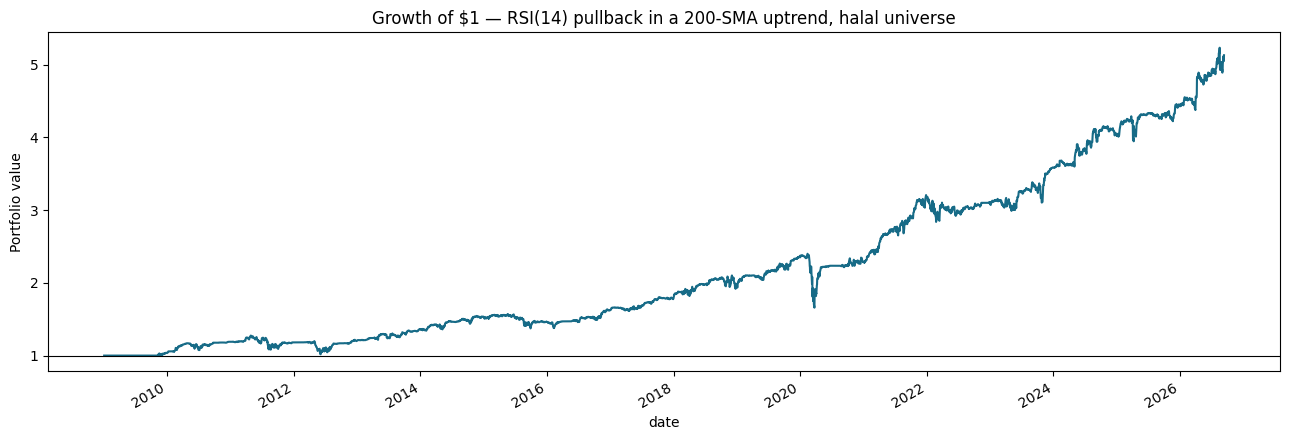

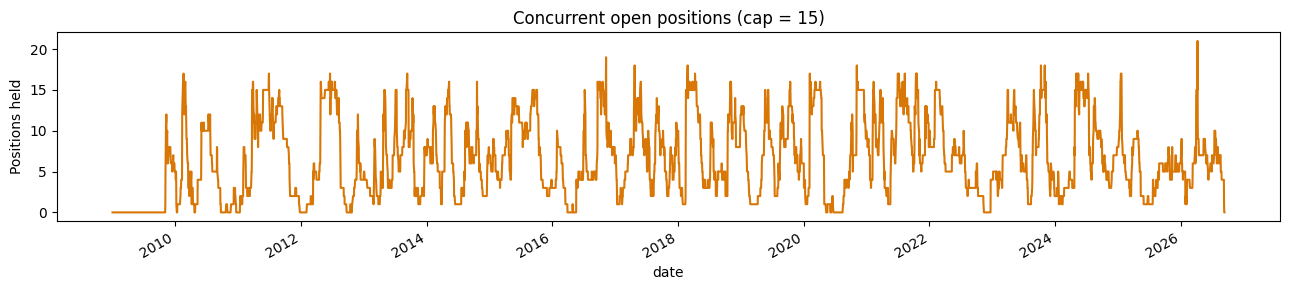

In [9]:
fig, ax = plt.subplots(figsize=(13, 4.5))
nav.plot(ax=ax, color='#176b87', title='Growth of $1 — RSI(14) pullback in a 200-SMA uptrend, halal universe')
ax.set_ylabel('Portfolio value')
ax.axhline(1, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 3))
open_count = pd.Series(0, index=dates)
for t in trades.itertuples():
    open_count.loc[t.entry_date:t.exit_date] += 1
open_count.plot(ax=ax, color='#d97706', title=f'Concurrent open positions (cap = {MAX_POSITIONS})')
ax.set_ylabel('Positions held')
plt.tight_layout()
plt.show()

## Monthly performance

The daily NAV series resampled to month-end, so this strategy can be read on the same monthly
heatmap as the other notebooks even though it actually trades on daily signals.

In [10]:
monthly_nav = nav.resample('ME').last()
today_ts = pd.Timestamp.now(tz='UTC')
if len(monthly_nav) and (monthly_nav.index[-1].year, monthly_nav.index[-1].month) == (today_ts.year, today_ts.month):
    monthly_nav = monthly_nav.iloc[:-1]
monthly_returns = monthly_nav.pct_change().dropna()

table = (monthly_returns * 100).rename('ret').to_frame()
table['year'] = table.index.year
table['month'] = table.index.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_table = table.pivot(index='year', columns='month', values='ret').reindex(columns=month_order)

annual_return = monthly_returns.groupby(monthly_returns.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
monthly_table['Year'] = annual_return

monthly_summary = pd.Series({
    'months': len(monthly_returns),
    'positive_months': int((monthly_returns > 0).sum()),
    'pct_positive_months': float((monthly_returns > 0).mean()),
    'avg_monthly_return': float(monthly_returns.mean()),
    'median_monthly_return': float(monthly_returns.median()),
    'best_month': monthly_returns.idxmax().strftime('%Y-%m'),
    'best_month_return': float(monthly_returns.max()),
    'worst_month': monthly_returns.idxmin().strftime('%Y-%m'),
    'worst_month_return': float(monthly_returns.min()),
})

styled = (
    monthly_table.round(1)
    .style.format(precision=1, na_rep='')
    .background_gradient(cmap='RdYlGn', axis=None, vmin=-15, vmax=15, subset=month_order)
    .set_caption('Monthly return (%) by year')
)
display(styled)
display(monthly_summary.to_frame('value'))

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year
year,,,,,,,,,,,,,
2009,,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.8,2.6,3.4
2010,2.2,2.3,6.2,1.7,-2.3,-5.4,6.0,-1.0,4.0,0.2,-0.2,1.0,15.0
2011,-0.4,1.1,3.6,2.7,-1.5,-2.7,-0.5,-4.5,-4.2,5.7,-0.1,0.6,-0.7
2012,0.0,0.1,0.3,0.4,-10.9,4.0,-0.5,5.8,0.7,0.2,2.3,0.5,1.9
2013,0.8,0.5,1.8,0.3,4.2,-3.9,3.2,-2.5,4.3,2.1,0.3,1.8,13.4
2014,-0.8,4.8,0.8,-2.7,4.4,0.8,0.4,2.4,-1.3,3.1,-0.2,-0.0,12.0
2015,-1.4,3.3,-0.9,0.6,-0.3,-1.7,-0.2,-4.9,-2.8,4.0,0.7,-0.4,-4.3
2016,-0.4,-1.0,1.9,0.1,0.5,-0.4,3.0,0.8,-0.2,0.9,4.2,1.2,11.0
2017,2.1,-0.2,-1.3,1.1,-0.4,2.6,2.6,0.9,1.5,1.2,-0.3,-0.5,9.3


,value
months,211
positive_months,127
pct_positive_months,0.601896
avg_monthly_return,0.008032
median_monthly_return,0.005247
best_month,2020-04
best_month_return,0.173405
worst_month,2020-03
worst_month_return,-0.118884


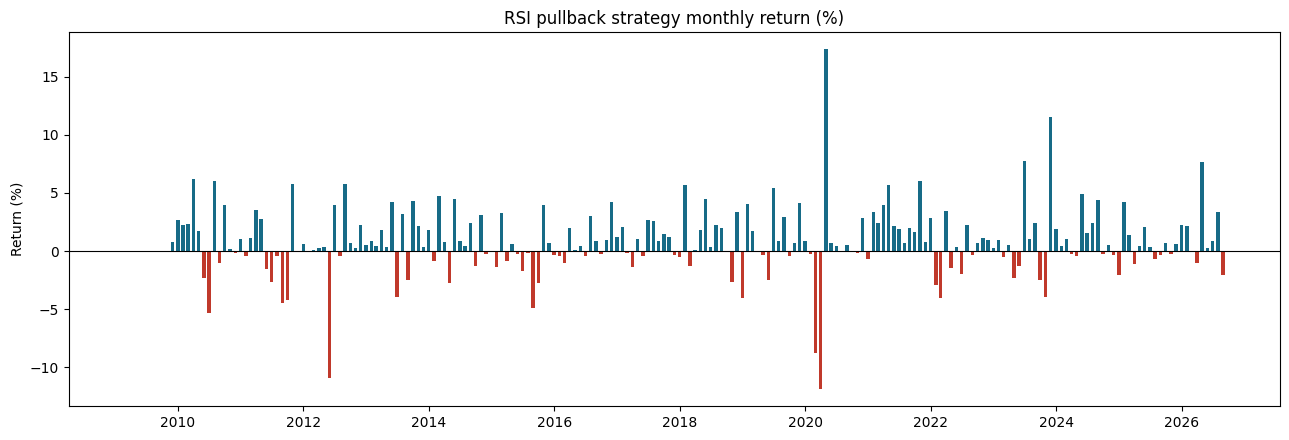

In [11]:
colors = np.where(monthly_returns >= 0, '#176b87', '#c0392b')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(monthly_returns.index, monthly_returns.values * 100, width=20, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('RSI pullback strategy monthly return (%)')
ax.set_ylabel('Return (%)')
plt.tight_layout()
plt.show()

## Caveats and next improvements

- **No transaction costs or slippage**: RSI exits and the profit target are assumed to fill at
  exactly their trigger price, same simplification as the breakout notebook.
- **No timeout on the armed state**: once a name is armed (RSI dipped below 35 in an uptrend), it
  stays armed indefinitely waiting for a 20-day SMA cross, with no expiry. In practice a stock
  can stay "watched" for a long stretch without ever confirming, which this backtest allows for
  free — a live trader might drop the setup after some number of days.
- **Equal-weight-of-NAV sizing**: every one of the 15 slots gets an equal dollar amount regardless
  of how oversold the name is or how volatile it's been, similar to the breakout notebook's
  simplification.
- **Same-bar signal and fill**: the SMA crossover and RSI checks use today's close, and the trade
  is assumed to fill at that same close.
- **Payoff shape is the opposite of trend-following, and that cuts both ways**: exiting at RSI 60
  or a 10% gain means this strategy systematically sells into strength and gives up the large
  winners a trend-following system is designed to capture. The very high win rate this notebook
  reports is not the same thing as the best total return — see the trade statistics and general
  statistics sections together, not in isolation.
- **Look-ahead / survivorship bias in the universe**: `equities-list.csv` is today's list of halal
  candidates, projected backward, same caveat as every other notebook in this project.
- A serious version of this strategy would need realistic slippage, a timeout or invalidation rule
  on the armed state, and probably a side-by-side comparison against the breakout notebook to see
  how a mean-reversion sleeve and a trend-following sleeve would actually combine in one book.